In [5]:
from src.model import RigParameters, RigSolver, DistanceCalculator

RIG = {
    "reach_left":         45.5,   # was 44.0   (+1.5)
    "reach_right":        46.3,   # was 44.8   (+1.5)
    "arm_height_left":    83.7,   # was 83.0   (+0.7)
    "arm_height_right":   83.5,   # was 84.0   (-0.5)
    "brace_left":         63.0,   # unchanged
    "brace_right":        63.0,   # unchanged
    "joint_height":      125.5,   # was 127.0  (-1.5)
    "pole_length":        84.5,   # was 83.0   (+1.5)
    "arm_half_angle_deg": 45.0,
    "mast_tilt_deg":       0.0,
}

In [6]:
# ── enter one (range_left, range_right) pair per can ───────────
can_ranges = [
    (115.9, 101.1),   # can 0
    (104.1, 107.4),   # can 1
  # (115.0, 100.0),   # can 2  ← uncomment to add a third can
]
# ───────────────────────────────────────────────────────────────

In [7]:
positions = []
for i, (rL, rR) in enumerate(can_ranges):
    params = RigParameters(
        aL=RIG["reach_left"],  aR=RIG["reach_right"],
        hL=RIG["arm_height_left"], hR=RIG["arm_height_right"],
        bL=RIG["brace_left"],  bR=RIG["brace_right"],
        hJ=RIG["joint_height"], Lp=RIG["pole_length"],
        rL=rL, rR=rR,
    )
    result = RigSolver(params).solve()
    positions.append((result['x'], result['y']))
    print(f"Can {i} : x={result['x']:.1f} cm,  y={result['y']:.1f} cm")
    for w in result['warnings']:
        print(f"  WARNING : {w}")

print()
calc = DistanceCalculator(*positions)
for label, dist in calc.all_distances().items():
    print(f"{label} : {dist:.1f} cm")

Can 0 : x=-56.8 cm,  y=132.8 cm
Can 1 : x=12.1 cm,  y=155.4 cm

post -> can 0 : 144.4 cm
post -> can 1 : 155.9 cm
can 0 -> can 1 : 67.2 cm


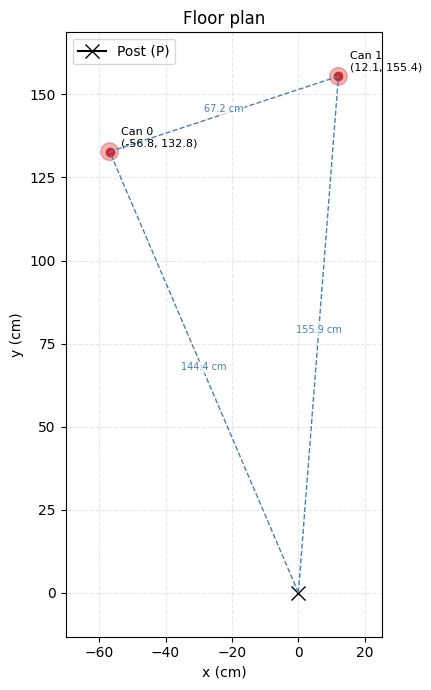

In [8]:
from src.visualise import FloorPlot

FloorPlot(positions).show()